Part A

In [344]:
import numpy as np

X = np.array([1, 2, 3, 4, 5, 6])
y = np.array([48, 52, 58, 64, 70, 75])

Task 1 - Understand the Problem

1.Input feature- Hours Studied

Target Variable - Exam Score

Type of supervised learning - Regression

Text(0, 0.5, 'Exam Score')

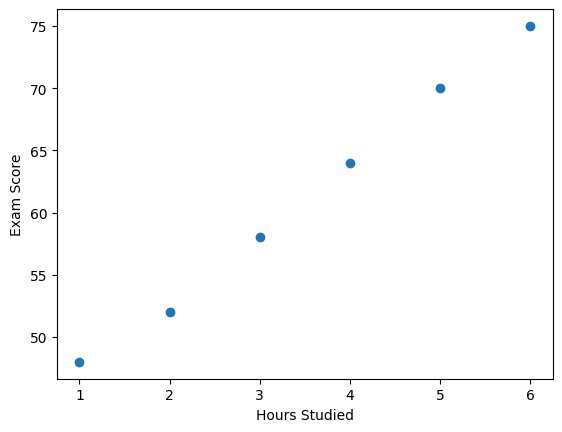

In [345]:
#2
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

3.Displays a strong positive linear relationship between the 'Hours Studied' and the 'Exam Score'.

A.2 – Build the Prediction Function

In [346]:
def predict(X, beta0, beta1):
    return beta0 + beta1 * X

beta0 = 0
beta1 = 0

y_hat = predict(X, beta0, beta1)
print(y_hat)

[0 0 0 0 0 0]


A.3 - Residuals & Mean Squared Error

In [347]:
#1
residuals = y - y_hat
print(residuals)

[48 52 58 64 70 75]


In [348]:
#2
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

In [349]:
#3
for actual, predicted, residual in zip(y, y_hat, residuals):
    print("Actual:", actual,
          "Predicted:", predicted,
          "Residual:", residual)

Actual: 48 Predicted: 0 Residual: 48
Actual: 52 Predicted: 0 Residual: 52
Actual: 58 Predicted: 0 Residual: 58
Actual: 64 Predicted: 0 Residual: 64
Actual: 70 Predicted: 0 Residual: 70
Actual: 75 Predicted: 0 Residual: 75


A.4 – Train Linear Regression using Gradient Descent


In [350]:
#1,2,3,4,5
learning_rate = 0.01
iterations = 1000

beta0 = 0
beta1 = 0

loss_history = []

for i in range(iterations):

    y_hat = predict(X, beta0, beta1)

    dbeta0 = (2 / len(X)) * np.sum(y_hat - y)
    dbeta1 = (2 / len(X)) * np.sum((y_hat - y) * X)

    beta0 = beta0 - learning_rate * dbeta0
    beta1 = beta1 - learning_rate * dbeta1

    current_mse = mse(y, predict(X, beta0, beta1))
    loss_history.append(current_mse)

print("beta0:", beta0)
print("beta1:", beta1)
print("MSE:", loss_history[-1])

beta0: 40.677869855813654
beta1: 5.802391188768685
MSE: 0.45798128772620866


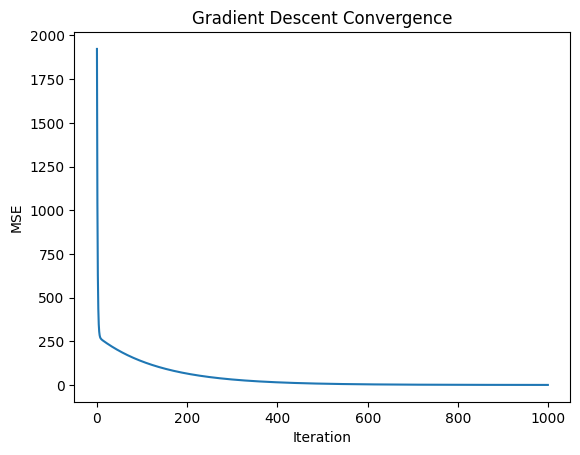

In [351]:
#6
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Gradient Descent Convergence")
plt.show()

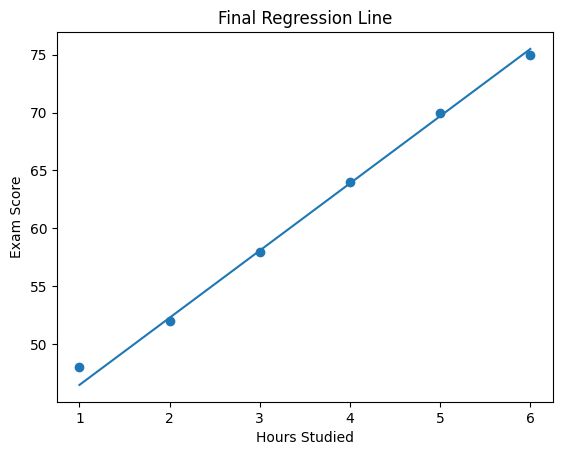

In [352]:
#7
final_predictions = predict(X, beta0, beta1)

plt.scatter(X, y)
plt.plot(X, final_predictions)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Final Regression Line")
plt.show()

A.5 – Evaluate the Regression Model


In [353]:
def mae(y, y_hat):
    return np.mean(np.abs(y - y_hat))

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

def rmse(y, y_hat):
    return np.sqrt(mse(y, y_hat))

def r2(y, y_hat):
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - (ss_res / ss_tot)

predictions = predict(X, beta0, beta1)

print("MAE:", mae(y, predictions))
print("MSE:", mse(y, predictions))
print("RMSE:", rmse(y, predictions))
print("R2:", r2(y, predictions))

MAE: 0.4670651981281135
MSE: 0.45798128772620866
RMSE: 0.6767431475280771
R2: 0.9949564618054012


In [354]:
#5
score = predict(4.5, beta0, beta1)
print(score)

66.78863020527274


A.6 – Verify using Scikit-learn


In [355]:
from sklearn.linear_model import LinearRegression

X_2d = X.reshape(-1, 1)

model = LinearRegression()
model.fit(X_2d, y)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("4.5 hour prediction:", model.predict([[4.5]])[0])

Intercept: 41.666666666666664
Coefficient: 5.571428571428571
4.5 hour prediction: 66.73809523809524


Part B


B.1 – Binary Classification Dataset


In [356]:
import numpy as np
import matplotlib.pyplot as plt

# Part B SVM dataset
X = np.array([
    [1, 2],
    [2, 2],
    [2, 3],
    [4, 4],
    [5, 4],
    [5, 5]
])

y = np.array([-1, -1, -1, 1, 1, 1])

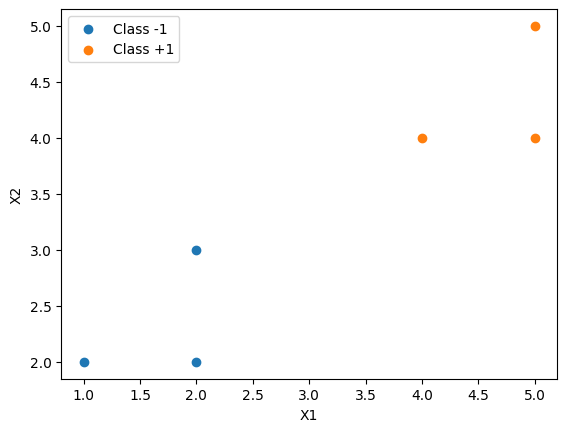

In [357]:
plt.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    label="Class -1"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class +1"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.legend()
plt.show()

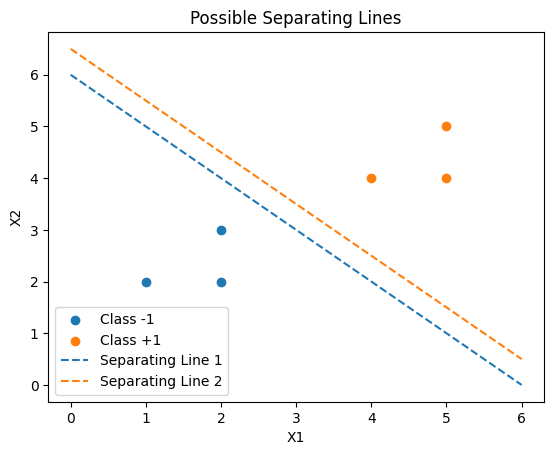

In [358]:
#3
x_line = np.linspace(0, 6, 100)

plt.scatter(X[y == -1, 0], X[y == -1, 1], label="Class -1")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class +1")

# Two possible separating lines
plt.plot(x_line, -x_line + 6, "--", label="Separating Line 1")
plt.plot(x_line, -x_line + 6.5, "--", label="Separating Line 2")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Possible Separating Lines")
plt.legend()
plt.show()

B.2 – SVM Decision Function


Task 7 – Fit an SVC and Inspect Its Decision Function


In [359]:
from sklearn.svm import SVC

svc = SVC(kernel='linear', C=1.0)
svc.fit(X, y)

w = svc.coef_[0]
b = svc.intercept_[0]

scores = X @ w + b
preds = svc.predict(X)

print(w)
print(b)
print(scores)
print(preds)

[0.8 0.4]
-3.8000000000000003
[-2.2 -1.4 -1.   1.   1.8  2.2]
[-1 -1 -1  1  1  1]


In [360]:
print("Scores match:",
      np.allclose(scores, svc.decision_function(X)))

print("Predictions match actual classes:",
      np.array_equal(preds, y))

Scores match: True
Predictions match actual classes: True


B.3 – Margin & Support Vectors


Task 8 – Investigate the Margin


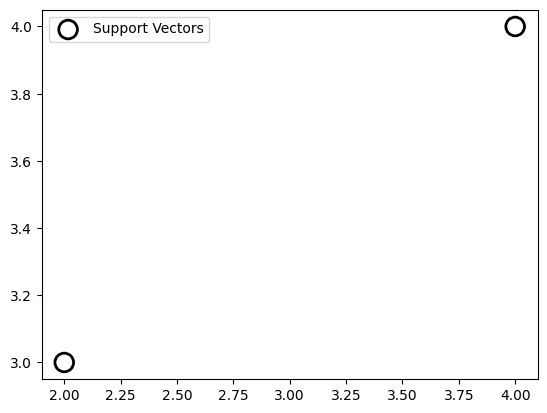

In [361]:
support_vectors = svc.support_vectors_

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.legend()

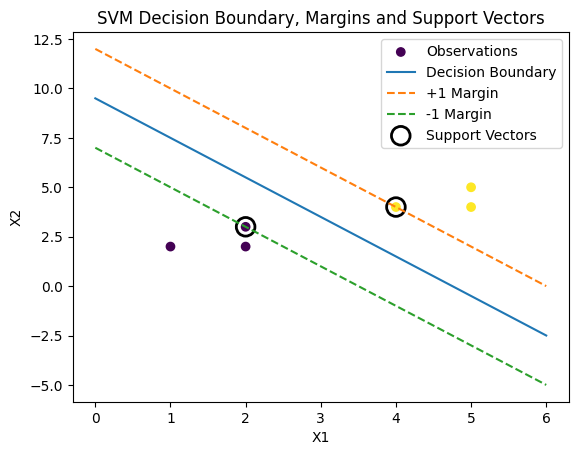

Support Vectors:
[[2. 3.]
 [4. 4.]]


In [362]:
xx = np.linspace(0, 6, 100)

decision = -(w[0] * xx + b) / w[1]
margin_pos = (1 - w[0] * xx - b) / w[1]
margin_neg = (-1 - w[0] * xx - b) / w[1]

plt.scatter(X[:, 0], X[:, 1], c=y, label="Observations")

plt.plot(xx, decision, label="Decision Boundary")
plt.plot(xx, margin_pos, "--", label="+1 Margin")
plt.plot(xx, margin_neg, "--", label="-1 Margin")

support_vectors = svc.support_vectors_

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Decision Boundary, Margins and Support Vectors")
plt.legend()
plt.show()

print("Support Vectors:")
print(svc.support_vectors_)

In [363]:
#2
print(svc.support_vectors_)

[[2. 3.]
 [4. 4.]]


B.4 – Hinge Loss


Task 9 – Hinge Loss from the Fitted Model


In [364]:
scores = svc.decision_function(X)

hinge = np.maximum(0, 1 - y * scores)

print(hinge)

[0. 0. 0. 0. 0. 0.]


B.5 – Interactive Sandbox: The Effect of C on the Margin


In [365]:
X = np.array([
    [1, 2],
    [2, 2],
    [2, 3],
    [4, 4],
    [5, 4],
    [5, 5]
])

y = np.array([-1, -1, -1, 1, 1, 1])

Task 10


In [366]:
C_values = [0.05, 0.1, 0.3, 1.0]

for C in C_values:
    model = SVC(kernel="linear", C=C)
    model.fit(X, y)

    margin_width = 2 / np.linalg.norm(model.coef_[0])

    print(
        "C =", C,
        "| Margin Width =", round(margin_width, 3),
        "| Support Vectors =", model.support_
    )

C = 0.05 | Margin Width = 4.986 | Support Vectors = [0 1 2 3 4 5]
C = 0.1 | Margin Width = 3.601 | Support Vectors = [1 2 3 4]
C = 0.3 | Margin Width = 2.981 | Support Vectors = [2 3]
C = 1.0 | Margin Width = 2.236 | Support Vectors = [2 3]


Part C


In [367]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 3, 4, 5, 6]).reshape(-1, 1)
y = np.array([48, 52, 58, 64, 70, 75])

print(X)
print(y)

[[1]
 [2]
 [3]
 [4]
 [5]
 [6]]
[48 52 58 64 70 75]


In [368]:
X.shape

(6, 1)

Task 11 – Fit an SVR and Inspect Its Predictions


In [369]:
from sklearn.svm import SVR

svr = SVR(kernel='linear', C=1.0, epsilon=1.0)
svr.fit(X, y)

w = svr.coef_[0][0]
b = svr.intercept_[0]

preds = w * X.ravel() + b

In [370]:
SVR(kernel='linear', C=1.0, epsilon=1.0)

SVR(epsilon=1.0, kernel='linear')

In [371]:
#1
from sklearn.svm import SVR

svr = SVR(kernel='linear', C=1.0, epsilon=1.0)

svr.fit(X, y)

SVR(epsilon=1.0, kernel='linear')

In [372]:
#2
w = svr.coef_[0][0]
b = svr.intercept_[0]

print("w =", w)
print("b =", b)

w = 5.0
b = 44.0


In [373]:
hand_predictions = w * X.ravel() + b

print(hand_predictions)

[49. 54. 59. 64. 69. 74.]


In [374]:
##3
sklearn_predictions = svr.predict(X)

print("Hand predictions:")
print(hand_predictions)

print("SVR predictions:")
print(sklearn_predictions)

Hand predictions:
[49. 54. 59. 64. 69. 74.]
SVR predictions:
[49. 54. 59. 64. 69. 74.]


In [375]:
print(np.allclose(hand_predictions, sklearn_predictions))

True


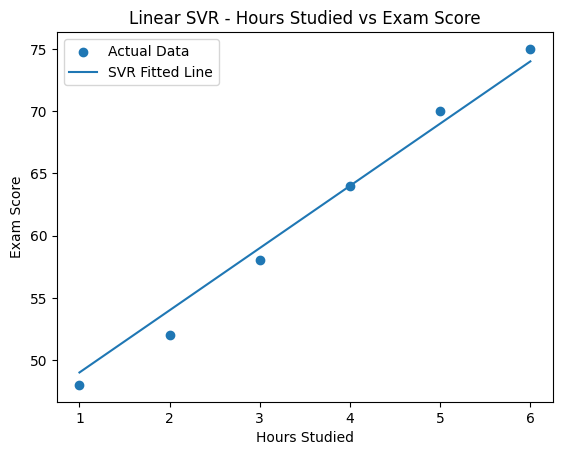

In [376]:
#4
plt.scatter(X.ravel(), y, label="Actual Data")

plt.plot(
    X.ravel(),
    sklearn_predictions,
    label="SVR Fitted Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Linear SVR - Hours Studied vs Exam Score")

plt.legend()
plt.show()

C.2 – Construct the ε-Tube


Task 12 — Visualize the ε-Tube

In [377]:
#1
preds = svr.predict(X)

upper = preds + svr.epsilon
lower = preds - svr.epsilon

print("Predictions:")
print(preds)

print("Upper boundary:")
print(upper)

print("Lower boundary:")
print(lower)

Predictions:
[49. 54. 59. 64. 69. 74.]
Upper boundary:
[50. 55. 60. 65. 70. 75.]
Lower boundary:
[48. 53. 58. 63. 68. 73.]


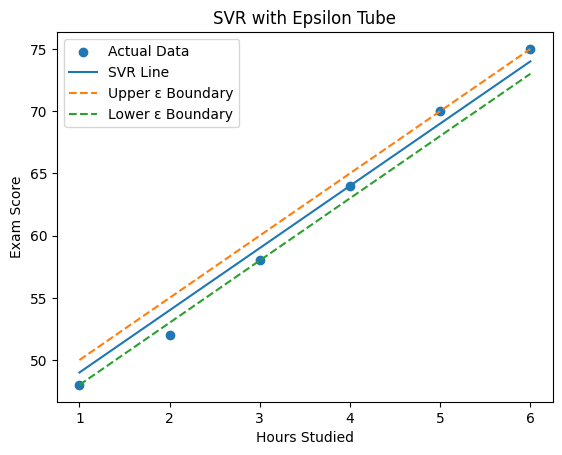

In [378]:
#2
plt.scatter(X.ravel(), y, label="Actual Data")

plt.plot(
    X.ravel(),
    preds,
    label="SVR Line"
)

plt.plot(
    X.ravel(),
    upper,
    "--",
    label="Upper ε Boundary"
)

plt.plot(
    X.ravel(),
    lower,
    "--",
    label="Lower ε Boundary"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("SVR with Epsilon Tube")

plt.legend()
plt.show()

In [379]:
#3
print(svr.support_)

[1 2 4 5]


In [380]:
print("Support vector indices:")
print(svr.support_)

Support vector indices:
[1 2 4 5]


In [381]:
print("Support vector X values:")
print(X[svr.support_])

print("Support vector y values:")
print(y[svr.support_])

Support vector X values:
[[2]
 [3]
 [5]
 [6]]
Support vector y values:
[52 58 70 75]


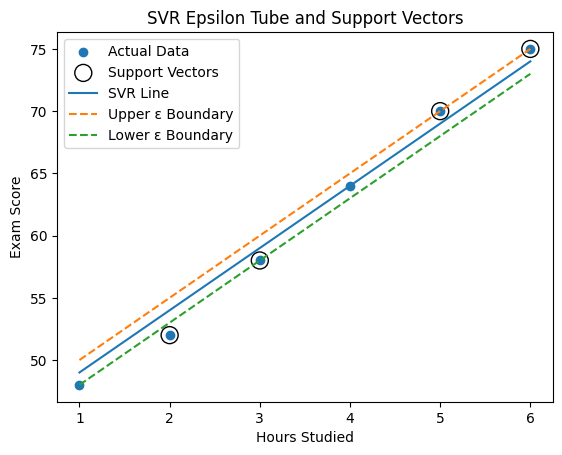

In [382]:
plt.scatter(X.ravel(), y, label="Actual Data")

plt.scatter(
    X[svr.support_].ravel(),
    y[svr.support_],
    s=150,
    facecolors="none",
    edgecolors="black",
    label="Support Vectors"
)

plt.plot(X.ravel(), preds, label="SVR Line")
plt.plot(X.ravel(), upper, "--", label="Upper ε Boundary")
plt.plot(X.ravel(), lower, "--", label="Lower ε Boundary")

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("SVR Epsilon Tube and Support Vectors")

plt.legend()
plt.show()

In [383]:
#4
inside = np.abs(y - svr.predict(X)) < svr.epsilon

In [384]:
inside = np.abs(y - svr.predict(X)) < svr.epsilon

print(inside)

[False False False  True False False]


In [385]:
for i in range(len(y)):
    print(
        "Student", chr(65 + i),
        "| Actual:", y[i],
        "| Predicted:", round(preds[i], 2),
        "| Error:", round(abs(y[i] - preds[i]), 2),
        "| Strictly Inside:", inside[i]
    )

Student A | Actual: 48 | Predicted: 49.0 | Error: 1.0 | Strictly Inside: False
Student B | Actual: 52 | Predicted: 54.0 | Error: 2.0 | Strictly Inside: False
Student C | Actual: 58 | Predicted: 59.0 | Error: 1.0 | Strictly Inside: False
Student D | Actual: 64 | Predicted: 64.0 | Error: 0.0 | Strictly Inside: True
Student E | Actual: 70 | Predicted: 69.0 | Error: 1.0 | Strictly Inside: False
Student F | Actual: 75 | Predicted: 74.0 | Error: 1.0 | Strictly Inside: False


Task 13 — ε-Insensitive Loss

In [386]:
#1
preds = svr.predict(X)

print(preds)

[49. 54. 59. 64. 69. 74.]


In [387]:
#2
loss = np.maximum(
    0,
    np.abs(y - preds) - svr.epsilon
)

print(loss)

[0. 1. 0. 0. 0. 0.]


In [388]:
np.maximum(0, np.abs(y - preds) - svr.epsilon)

array([0., 1., 0., 0., 0., 0.])

In [389]:
#3
absolute_error = np.abs(y - preds)

for i in range(len(y)):
    print(
        "Student", chr(65 + i),
        "| Actual:", y[i],
        "| Predicted:", round(preds[i], 2),
        "| Absolute Error:", round(absolute_error[i], 2),
        "| Loss:", round(loss[i], 2)
    )

Student A | Actual: 48 | Predicted: 49.0 | Absolute Error: 1.0 | Loss: 0.0
Student B | Actual: 52 | Predicted: 54.0 | Absolute Error: 2.0 | Loss: 1.0
Student C | Actual: 58 | Predicted: 59.0 | Absolute Error: 1.0 | Loss: 0.0
Student D | Actual: 64 | Predicted: 64.0 | Absolute Error: 0.0 | Loss: 0.0
Student E | Actual: 70 | Predicted: 69.0 | Absolute Error: 1.0 | Loss: 0.0
Student F | Actual: 75 | Predicted: 74.0 | Absolute Error: 1.0 | Loss: 0.0


In [390]:
import pandas as pd

results = pd.DataFrame({
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Actual": y,
    "Predicted": preds,
    "Absolute Error": absolute_error,
    "Epsilon Loss": loss
})

print(results)

  Student  Actual  Predicted  Absolute Error  Epsilon Loss
0       A      48       49.0             1.0           0.0
1       B      52       54.0             2.0           1.0
2       C      58       59.0             1.0           0.0
3       D      64       64.0             0.0           0.0
4       E      70       69.0             1.0           0.0
5       F      75       74.0             1.0           0.0


In [391]:
print("Loss:", loss)
print("Support indices:", svr.support_)

Loss: [0. 1. 0. 0. 0. 0.]
Support indices: [1 2 4 5]


Task 14 – The Effect of ε on the Tube


In [392]:
epsilon_values = [0.1, 0.5, 1, 3]

for epsilon in epsilon_values:

    model = SVR(
        kernel="linear",
        C=1.0,
        epsilon=epsilon
    )

    model.fit(X, y)

    print(
        "epsilon =", epsilon,
        "| slope =", model.coef_[0][0],
        "| support vectors =", model.support_
    )

epsilon = 0.1 | slope = 5.399999999999999 | support vectors = [0 1 2 3 4 5]
epsilon = 0.5 | slope = 5.333333333333333 | support vectors = [1 2 4 5]
epsilon = 1 | slope = 5.0 | support vectors = [1 2 4 5]
epsilon = 3 | slope = 4.0 | support vectors = [1 5]
